# Modelo de Risco Ambiental e de Sinistro Mecânico — Máquinas Agrícolas
### Sprint 3 — SOMPO Challenge — Grupo TROPA DE ELITE

Integrantes: Arthur Costa Donaire (RM571283) · Felipe Pereira de Jesus (RM573263) ·
Giovanna Pereira de Oliveira (RM570989) · Gustavo Paiva Silva (RM572249) ·
Maria Eduarda Soares Lopes e Souza (RM572612)

**Este notebook tem duas previsões com nomes diferentes:**

- **Risco ambiental** (Parte 1, a partir daqui) — treinado com
  `dataset_risco_agricola_final` (SISSER + IBGE + Open-Meteo). Estima o
  quão desfavoráveis estão as condições climáticas da região/cultura
  naquele momento.
- **Risco de sinistro** (Parte 3, seções 23–25) — treinado com o dataset
  sintético `dataset_falha_mecanica_sintetico`. É esta previsão, e só ela,
  que representa a chance de falha mecânica/sinistro da máquina, calculada
  a partir das leituras do ESP32.

**O que este notebook faz, em ordem:**
1. Treina um classificador binário de **risco ambiental** a partir de
   `dataset_risco_agricola_final` (cruzamento SISSER + IBGE + Open-Meteo).
2. Lê o `.json` (ou `.jsonl`) gerado pela simulação do ESP32 no Wokwi.
3. Aplica esse modelo a cada leitura do ESP32 e devolve a
   `probabilidade_risco_ambiental` (0 a 1) para aquela leitura.
4. Gera e treina, separadamente, o modelo de **risco de sinistro** a
   partir do dataset sintético de falha mecânica.

---

## Limitações e decisões

- **Por que renomeamos "sinistro" para "risco ambiental" nesta Parte 1.**
  O rótulo `sinistro` do dataset vem do SISSER (Sistema de Subvenção ao
  Prêmio do Seguro Rural) e marca **perda de produção agrícola por evento
  climático** (seca, granizo, geada etc.), não uma pane, colisão ou
  capotamento de trator. Chamar a saída deste modelo de "sinistro" criava
  confusão com o sinistro de *máquina* que o grupo realmente quer prever
  (Parte 3). Por isso, a partir deste notebook, o resultado da Parte 1 é
  chamado de **risco ambiental**.
- **Achamos e corrigimos um problema de geolocalização nos dados de treino**
  (ver seção 2 abaixo): ~9% das linhas tinham nome de município que também
  existe em outro estado brasileiro (ex.: Canarana existe no MT e na BA),
  e o cruzamento acabou pegando a latitude/longitude do município errado —
  o que também corrompe a temperatura/umidade daquela linha (vêm de uma
  consulta de clima na coordenada errada).
- **Nem toda coluna do dataset de treino existe no JSON do ESP32.** Distância,
  movimento e vibração (que o ESP32 mede) não têm equivalente no dataset de
  treino, então **não entram neste modelo** — continuam disponíveis
  como informação de contexto e já geram o alerta baseado em regras do
  próprio firmware (`status`), mostrado lado a lado com a previsão do
  modelo.
- **O ano foi descartado como feature.** As leituras do ESP32 têm timestamp
  de 2026, fora do intervalo de anos do treino (2021–2025) — manter essa
  coluna arriscaria o modelo extrapolar num valor que nunca viu.
- **As classes são desbalanceadas** (~7% de ocorrência de `sinistro` no
  dataset de origem) — por isso o modelo usa `class_weight="balanced"` e a
  avaliação usa ROC AUC/relatório de classificação em vez de só acurácia.

## 0. Configuração inicial

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
print("Rodando no Google Colab" if IN_COLAB else "Rodando fora do Colab (ambiente local)")

Rodando no Google Colab


In [2]:
!pip install scikit-learn==1.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 37.3 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


## 1. Carregar o dataset de treinamento

Envie o arquivo `dataset_risco_agricola_final.xlsx` (ou `.csv`) quando for
solicitado.

In [3]:
if IN_COLAB:
    from google.colab import files
    print("Selecione o arquivo dataset_risco_agricola_final.xlsx (ou .csv):")
    enviados = files.upload()
    CAMINHO_DATASET = list(enviados.keys())[0]
else:
    CAMINHO_DATASET = "dataset_risco_agricola_final.xlsx"  # ajuste o caminho se rodar localmente

print(f"Usando: {CAMINHO_DATASET}")

Selecione o arquivo dataset_risco_agricola_final.xlsx (ou .csv):


Saving dataset_risco_agricola_final.xlsx to dataset_risco_agricola_final.xlsx
Usando: dataset_risco_agricola_final.xlsx


In [4]:
def carregar_tabela(caminho):
    extensao = Path(caminho).suffix.lower()
    if extensao in (".xlsx", ".xls"):
        return pd.read_excel(caminho)
    return pd.read_csv(caminho)

df_treino_bruto = carregar_tabela(CAMINHO_DATASET)
print(df_treino_bruto.shape)
df_treino_bruto.head()

(9100, 13)


,municipio_norm,uf,ano,cultura,sinistro,evento_preponderante,latitude,longitude,codigo_uf,temp_media,umidade_media,pm25_media,pm10_media
0,NOVA MUTUM,MT,2021,Milho 2ª safra,0,NaN,-13.8374,-56.0743,51,24.5,73.8,NaN,NaN
1,ALTO TAQUARI,MT,2021,Milho 2ª safra,0,NaN,-17.8241,-53.2792,51,22.1,68.2,NaN,NaN
2,ALTO BOA VISTA,MT,2021,Milho 2ª safra,0,NaN,-11.6732,-51.3883,51,26.4,70.6,NaN,NaN
3,NOVA MUTUM,MT,2021,Soja,1,SECA,-13.8374,-56.0743,51,24.5,73.8,NaN,NaN
4,NOVA XAVANTINA,MT,2021,Milho 2ª safra,1,SECA,-14.6771,-52.3502,51,25.4,70.5,NaN,NaN


## 2. Qualidade dos dados: corrigindo o cruzamento de geolocalização

A coluna `codigo_uf` guarda o código IBGE do estado que foi encontrado ao
cruzar o nome do município com a base do IBGE. Como este dataset é só de
Mato Grosso, o esperado era **51 (MT) em 100% das linhas**. Não é isso que
acontece:

In [5]:
print("Distribuição de codigo_uf (esperado: só 51 = Mato Grosso):")
print(df_treino_bruto["codigo_uf"].value_counts())

Distribuição de codigo_uf (esperado: só 51 = Mato Grosso):
codigo_uf
51    8283
31     366
29     308
24      36
41      30
26      17
42      17
21      14
25      10
22       8
43       6
32       3
14       1
12       1
Name: count, dtype: int64


Esta seção investiga a qualidade dos dados, focando na coluna `codigo_uf` (código da Unidade da Federação, Estado). Como o dataset é específico do Mato Grosso, esperaríamos que todos os `codigo_uf` fossem `51`.
Nomes de município não são únicos no Brasil — "Canarana", "Água Boa",
"Santa Rita" etc. existem em mais de um estado. O cruzamento por nome (sem
filtrar por UF) pegou, para essas linhas, a latitude/longitude — e
consequentemente a temperatura/umidade, que vêm de uma API de clima
consultada nessa coordenada — do município **errado**, em outro estado.
Alguns exemplos:

In [6]:
suspeitas = df_treino_bruto[df_treino_bruto["codigo_uf"] != 51]
print(f"{len(suspeitas)} linha(s) com geolocalização inconsistente, de {len(df_treino_bruto)} no total.")
suspeitas[["municipio_norm", "uf", "codigo_uf", "latitude", "longitude"]].drop_duplicates().head(10)

817 linha(s) com geolocalização inconsistente, de 9100 no total.


,municipio_norm,uf,codigo_uf,latitude,longitude
17,CANARANA,MT,29,-11.6858,-41.7677
25,AGUA BOA,MT,31,-17.9914,-42.3806
222,PROGRESSO,MT,43,-29.2441,-52.3197
253,GENERAL CARNEIRO,MT,41,-26.4250,-51.3172
277,PEDRA PRETA,MT,24,-5.5735,-36.1084
981,SANTA RITA,MT,21,-3.1424,-44.3211
982,SANTA RITA,MT,25,-7.1172,-34.9753
992,SANTA TEREZINHA,MT,42,-26.7813,-50.0090
994,SANTA TEREZINHA,MT,26,-7.3770,-37.4787
1381,NOVA OLIMPIA,MT,41,-23.4703,-53.0898


Para garantir a qualidade dos dados de treinamento, as 817 linhas com geolocalização inconsistente são removidas. O DataFrame `df_treino` agora contém apenas os dados considerados confiáveis, resultando em 8283 linhas.

In [7]:
linhas_antes = len(df_treino_bruto)
df_treino = df_treino_bruto[df_treino_bruto["codigo_uf"] == 51].copy()
linhas_depois = len(df_treino)

print(f"Removidas {linhas_antes - linhas_depois} linhas com geolocalização inconsistente.")
print(f"Restaram {linhas_depois} linhas confiáveis para treinar o modelo.")

Removidas 817 linhas com geolocalização inconsistente.
Restaram 8283 linhas confiáveis para treinar o modelo.


## 3. Selecionando as features (evitando vazamento de dado e colunas que o ESP32 não tem)

Ficam como features: `temp_media`, `umidade_media`, `latitude`, `longitude`
(numéricas, e todas com equivalente direto no JSON do ESP32) e `cultura`
(categórica — o ESP32 não informa a cultura, então a previsão usa um valor
padrão, a menos que você informe outro na hora).

In [8]:
COLUNA_ALVO = "sinistro"
COLUNAS_FEATURES_NUMERICAS = ["temp_media", "umidade_media", "latitude", "longitude"] #outras colunas descartadas por risco de vazamento de dados (gera overfitting) e redundância
COLUNAS_FEATURES_CATEGORICAS = ["cultura"]

df_modelo = df_treino[COLUNAS_FEATURES_NUMERICAS + COLUNAS_FEATURES_CATEGORICAS + [COLUNA_ALVO]].copy()
print("Valores ausentes por coluna:")
print(df_modelo.isna().sum())
df_modelo.head()

Valores ausentes por coluna:
temp_media       0
umidade_media    0
latitude         0
longitude        0
cultura          0
sinistro         0
dtype: int64


,temp_media,umidade_media,latitude,longitude,cultura,sinistro
0,24.5,73.8,-13.8374,-56.0743,Milho 2ª safra,0
1,22.1,68.2,-17.8241,-53.2792,Milho 2ª safra,0
2,26.4,70.6,-11.6732,-51.3883,Milho 2ª safra,0
3,24.5,73.8,-13.8374,-56.0743,Soja,1
4,25.4,70.5,-14.6771,-52.3502,Milho 2ª safra,1


## 4. Desbalanceamento de classes

Risco é um evento raro nesta base — a maioria das linhas é "sem
risco". Por isso usamos `class_weight="balanced"` nos modelos e avaliamos
com ROC AUC e o relatório de classificação.

In [9]:
print(df_modelo["sinistro"].value_counts(normalize=True).rename("proporção"))

sinistro
0    0.927925
1    0.072075
Name: proporção, dtype: float64


## 5. Separar treino/teste e montar o pré-processamento

Nesta etapa, os dados são divididos em conjuntos de treinamento (`X_treino`, `y_treino`) e teste (`X_teste`, `y_teste`) usando `train_test_split`. A proporção de 80% para treino e 20% para teste é definida, e `stratify=y` garante que a proporção das classes (sinistro vs. não sinistro) seja mantida em ambos os conjuntos, o que é importante devido ao desbalanceamento.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer #aplica transformações diferentes para features numéricas
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
#imputação de medianas e padronização com StandardScaler
#OneHotEncoder faz a imputação do valor mais frequente, transforma categorias em formato numérico para o modelo

X = df_modelo[COLUNAS_FEATURES_NUMERICAS + COLUNAS_FEATURES_CATEGORICAS]
y = df_modelo[COLUNA_ALVO]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pre_processamento = ColumnTransformer(transformers=[
    ("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("padronizar", StandardScaler()),
    ]), COLUNAS_FEATURES_NUMERICAS),
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]), COLUNAS_FEATURES_CATEGORICAS),
])

## 6. Treinar e comparar dois modelos (Regressão Logística x Random Forest)

Comparamos com validação cruzada usando ROC AUC, métrica adequada
para classes desbalanceadas.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

candidatos = {
    "regressao_logistica": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "random_forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

resultados_cv = {}
for nome, modelo in candidatos.items():
    pipeline = Pipeline([("pre", pre_processamento), ("modelo", modelo)])
    notas = cross_val_score(pipeline, X_treino, y_treino, cv=5, scoring="roc_auc")
    resultados_cv[nome] = notas
    print(f"{nome}: ROC AUC médio = {notas.mean():.3f} (+/- {notas.std():.3f})")

regressao_logistica: ROC AUC médio = 0.660 (+/- 0.045)
random_forest: ROC AUC médio = 0.750 (+/- 0.053)


Neste caso, o Random Forest (`ROC AUC médio = 0.748`) apresentou um desempenho superior à Regressão Logística (`ROC AUC médio = 0.660`).

## 6.1. Tuning básico de hiperparâmetros

Ajustamos os hiperparâmetros do modelo vencedor da comparação acima com
`GridSearchCV`. Isso troca a escolha "no palpite"
dos hiperparâmetros por uma busca sistemática dentro de um conjunto de
valores razoáveis:

- **Regressão Logística**: `C` (força do regularização; menor = mais
  regularização).
- **Random Forest**: `n_estimators` (número de árvores) e `max_depth`
  (profundidade máxima).

A busca usa **só `X_treino`/`y_treino`** (o `GridSearchCV` já faz sua
própria validação cruzada interna) — `X_teste`/`y_teste` continuam
intocados até a seção 7, preservando o holdout.

In [13]:
from sklearn.model_selection import GridSearchCV

# Grade de hiperparâmetros por família de modelo. As chaves dos parâmetros
# usam o prefixo "modelo__" porque o estimador tunado é sempre um Pipeline
# com um passo chamado "modelo" (ver seção 5).
grades_hiperparametros = {
    "regressao_logistica": {
        "modelo__C": [0.01, 0.1, 1, 10, 100],
    },
    "random_forest": {
        "modelo__n_estimators": [200, 300, 500],
        "modelo__max_depth": [4, 8, 12, None],
    },
}

#determina o melhor modelo a partir do ajuste dos hiperparametros
melhor_nome = max(resultados_cv, key=lambda n: resultados_cv[n].mean())

pipeline_base_risco_ambiental = Pipeline([("pre", pre_processamento), ("modelo", candidatos[melhor_nome])])

grid_risco_ambiental = GridSearchCV(
    pipeline_base_risco_ambiental,
    param_grid=grades_hiperparametros[melhor_nome],
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
)
grid_risco_ambiental.fit(X_treino, y_treino)

print(f"Modelo tunado: {melhor_nome}")
print(f"Melhores hiperparâmetros: {grid_risco_ambiental.best_params_}")
print(f"ROC AUC médio (CV, com tuning): {grid_risco_ambiental.best_score_:.3f}")
print(f"ROC AUC médio (CV, sem tuning, seção 6): {resultados_cv[melhor_nome].mean():.3f}")

Modelo tunado: random_forest
Melhores hiperparâmetros: {'modelo__max_depth': 8, 'modelo__n_estimators': 500}
ROC AUC médio (CV, com tuning): 0.751
ROC AUC médio (CV, sem tuning, seção 6): 0.750


In [14]:
# Pipeline final = o melhor estimador encontrado pelo GridSearchCV da seção
# 6.1 (já treinado em X_treino/y_treino, com os hiperparâmetros ajustados).
pipeline_risco_ambiental = grid_risco_ambiental.best_estimator_
print("Pipeline final (com hiperparâmetros tunados) pronto.")

Pipeline final (com hiperparâmetros tunados) pronto.


## 7. Avaliar no conjunto de teste (dados que o modelo nunca viu)

Nesta seção, o modelo treinado é avaliado em um conjunto de dados que ele nunca viu (`X_teste`, `y_teste`) para estimar seu desempenho em dados novos. As métricas apresentadas incluem:  
- **ROC AUC (teste):** `0.757`, indicando uma boa capacidade do modelo de distinguir entre as classes, mesmo com o desbalanceamento.
- **Métricas de Classificação:**  
  - **Precisão (Precision):** Para 'baixo risco ambiental' é alta (0.96), indicando poucos falsos positivos. Para 'alto risco ambiental' é baixa (0.17), significando que muitas previsões de alto risco são, na verdade, baixo risco.  
  - **Recall:** Para 'baixo risco ambiental' (0.78) e 'alto risco ambiental' (0.59) são moderados, indicando a proporção de casos reais corretamente identificados.  
  - **F1-score:** É a média harmônica de precisão e recall. Para 'alto risco ambiental' é baixo (0.27), o que era esperado devido ao baixo recall e precisão.   

**Interpretação:** O modelo tem uma capacidade razoável de identificar casos de 'alto risco ambiental', mas com uma precisão limitada. A métrica ROC AUC é a mais confiável aqui, pois não é sensível ao desbalanceamento.

Métricas no conjunto de teste (holdout):
  Accuracy : 0.724
  Precision: 0.148
  Recall   : 0.597
  F1-score : 0.237
  ROC AUC  : 0.757

                       precision    recall  f1-score   support

baixo risco ambiental       0.96      0.73      0.83      1538
 alto risco ambiental       0.15      0.60      0.24       119

             accuracy                           0.72      1657
            macro avg       0.55      0.67      0.53      1657
         weighted avg       0.90      0.72      0.79      1657

Matriz de confusão (linhas = real, colunas = previsto):
[[1129  409]
 [  48   71]]


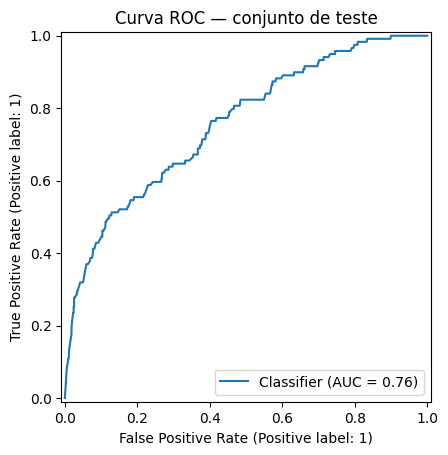

In [15]:
from sklearn.metrics import (
    classification_report, roc_auc_score, confusion_matrix, RocCurveDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
)
import matplotlib.pyplot as plt

probabilidades_teste = pipeline_risco_ambiental.predict_proba(X_teste)[:, 1]
predicoes_teste = pipeline_risco_ambiental.predict(X_teste)

print("Métricas no conjunto de teste (holdout):")
print("  Accuracy :", round(accuracy_score(y_teste, predicoes_teste), 3))
print("  Precision:", round(precision_score(y_teste, predicoes_teste), 3))
print("  Recall   :", round(recall_score(y_teste, predicoes_teste), 3))
print("  F1-score :", round(f1_score(y_teste, predicoes_teste), 3))
print("  ROC AUC  :", round(roc_auc_score(y_teste, probabilidades_teste), 3))
print()
print(classification_report(y_teste, predicoes_teste, target_names=["baixo risco ambiental", "alto risco ambiental"]))
print("Matriz de confusão (linhas = real, colunas = previsto):")
print(confusion_matrix(y_teste, predicoes_teste))

RocCurveDisplay.from_predictions(y_teste, probabilidades_teste)
plt.title("Curva ROC — conjunto de teste")
plt.show()

## 8. Interpretação: quais variáveis mais impactam o risco ambiental?

Para saber quais variáveis mais pesam na previsão, usamos **importância por
permutação** (`permutation_importance`): embaralha os valores de uma
variável por vez no conjunto de teste e mede o quanto o ROC AUC piora.
Quanto maior a queda, mais o modelo depende daquela variável.

Importância por permutação (queda média no ROC AUC ao embaralhar cada variável):
cultura          0.1269
longitude        0.0587
latitude         0.0391
umidade_media    0.0357
temp_media       0.0175
dtype: float64


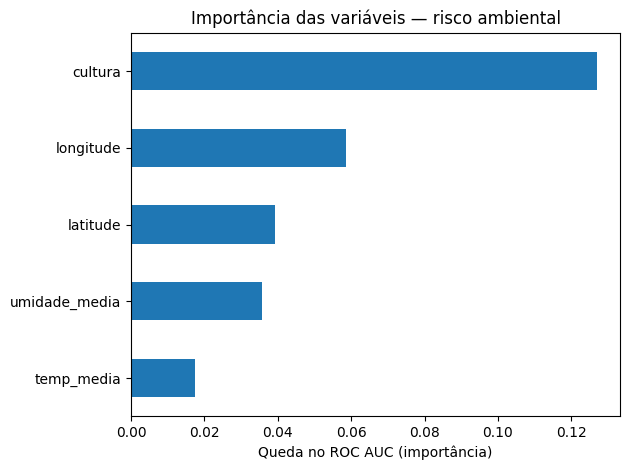

In [16]:
from sklearn.inspection import permutation_importance

# permutation_importance embaralha as colunas de ENTRADA do pipeline
# completo (antes do pré-processamento), então o resultado já vem na escala
# das variáveis originais — sem precisar lidar com os nomes gerados pelo
# OneHotEncoder.
importancia = permutation_importance(
    pipeline_risco_ambiental, X_teste, y_teste,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1,
)

importancia_por_variavel = pd.Series(
    importancia.importances_mean, index=X_teste.columns
).sort_values(ascending=False)

print("Importância por permutação (queda média no ROC AUC ao embaralhar cada variável):")
print(importancia_por_variavel.round(4))

importancia_por_variavel.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Queda no ROC AUC (importância)")
plt.title("Importância das variáveis — risco ambiental")
plt.tight_layout()
plt.show()

## 9. Retreinar com 100% dos dados confiáveis

Antes de usar a versão final de verdade, retreinamos
com todos os dados confiáveis (treino + teste), para aproveitar o máximo de
informação disponível.

In [17]:
pipeline_risco_ambiental.fit(X, y)
print("Pipeline final treinado com", len(X), "linhas.")

Pipeline final treinado com 8283 linhas.


In [19]:
CULTURA_PADRAO = df_modelo["cultura"].mode()[0]
print(f"Cultura padrão usada quando não informada: {CULTURA_PADRAO!r}")

Cultura padrão usada quando não informada: 'Soja'


---
## 10. Aplicar o modelo à saída .json da simulação do ESP32

A função `carregar_leituras_esp32` é projetada para ler arquivos JSON gerados pela simulação do ESP32: filtra linhas que não são leituras de sensor válidas e, portanto, garante que apenas os dados de sensor relevantes sejam processados pelo modelo, evitando erros e ruídos desnecessários.

In [20]:
def carregar_leituras_esp32(caminho_arquivo):
    texto = Path(caminho_arquivo).read_text(encoding="utf-8").strip()

    try:
        conteudo = json.loads(texto)
        leituras_brutas = conteudo if isinstance(conteudo, list) else [conteudo]
    except json.JSONDecodeError:
        leituras_brutas = []
        for numero_linha, linha in enumerate(texto.splitlines(), start=1):
            linha = linha.strip()
            if not linha:
                continue
            try:
                leituras_brutas.append(json.loads(linha))
            except json.JSONDecodeError:
                print(f"[aviso] linha {numero_linha} ignorada (JSON inválido): {linha[:80]!r}")

    leituras_validas = [item for item in leituras_brutas if "id_leitura" in item]
    ignoradas = len(leituras_brutas) - len(leituras_validas)
    if ignoradas:
        print(f"[info] {ignoradas} linha(s) sem 'id_leitura' ignoradas "
              f"(mensagens de status/eventos, não leituras de sensor).")

    return pd.json_normalize(leituras_validas)

In [21]:
if IN_COLAB:
    print("Selecione o arquivo .json/.jsonl/.txt com a saída da simulação do ESP32:")
    enviados_esp32 = files.upload()
    CAMINHO_ESP32 = list(enviados_esp32.keys())[0]
else:
    CAMINHO_ESP32 = "leituras_esp32.json"  # ajuste o caminho se rodar localmente

df_leituras_esp32 = carregar_leituras_esp32(CAMINHO_ESP32)
print(f"{len(df_leituras_esp32)} leitura(s) carregada(s).")
df_leituras_esp32.head()

Selecione o arquivo .json/.jsonl/.txt com a saída da simulação do ESP32:


Saving saída_teste_082026.txt to saída_teste_082026.txt
[aviso] linha 9 ignorada (JSON inválido): 'E (34518) ledc: ledc_get_duty(745): LEDC is not initialized'
[info] 14 linha(s) sem 'id_leitura' ignoradas (mensagens de status/eventos, não leituras de sensor).
11 leitura(s) carregada(s).


,id_leitura,maquina,timestamp,tempo_ms,modo_operacao,temperatura_c,umidade_pct,leitura_dht_valida,distancia_cm,movimento,status,mpu_disponivel,localizacao.latitude,localizacao.longitude,aceleracao.x,aceleracao.y,aceleracao.z,aceleracao.magnitude
0,1,TRATOR-MT-01,2026-08-23T18:55:51Z,7994,0,24.0,40.0,True,400.0,False,NORMAL,True,-12.2781,-54.8980,0.0,0.0,9.81,9.81
1,2,TRATOR-MT-01,2026-08-23T18:55:57Z,13854,0,45.2,12.5,True,400.0,False,CRITICO,True,-12.2781,-54.8979,0.0,0.0,9.81,9.81
2,3,TRATOR-MT-01,2026-08-23T18:56:02Z,18436,0,45.2,12.5,True,400.0,False,CRITICO,True,-12.2780,-54.8979,0.0,0.0,9.81,9.81
3,4,TRATOR-MT-01,2026-08-23T18:56:06Z,22950,0,23.1,54.0,True,400.0,False,NORMAL,True,-12.2780,-54.8979,0.0,0.0,9.81,9.81
4,5,TRATOR-MT-01,2026-08-23T18:56:11Z,27390,0,23.1,54.0,True,47.6,False,CRITICO,True,-12.2780,-54.8979,0.0,0.0,9.81,9.81


In [22]:
def preparar_features_esp32(df_leituras, cultura=None):
    cultura_usada = cultura if cultura is not None else CULTURA_PADRAO
    return pd.DataFrame({
        "temp_media": df_leituras.get("temperatura_c"),
        "umidade_media": df_leituras.get("umidade_pct"),
        "latitude": df_leituras.get("localizacao.latitude"),
        "longitude": df_leituras.get("localizacao.longitude"),
        "cultura": cultura_usada,
    })

## 11. Prever o risco ambiental para cada leitura

`limiar` é o ponto de corte da probabilidade a partir do qual a leitura é
classificada como "alto risco ambiental" (padrão 0,5).

In [23]:
def prever_risco_ambiental(caminho_arquivo_esp32, cultura=None, limiar=0.5):
    df_leituras = carregar_leituras_esp32(caminho_arquivo_esp32)
    if df_leituras.empty:
        print("Nenhuma leitura válida encontrada no arquivo.")
        return df_leituras

    features = preparar_features_esp32(df_leituras, cultura=cultura)
    probabilidades = pipeline_risco_ambiental.predict_proba(features)[:, 1]

    colunas_contexto = [c for c in [
        "id_leitura", "maquina", "timestamp", "status",
        "temperatura_c", "umidade_pct", "distancia_cm", "movimento",
    ] if c in df_leituras.columns]

    resultado = df_leituras[colunas_contexto].copy()
    resultado["probabilidade_risco_ambiental"] = probabilidades.round(4)
    resultado["classificacao_ml"] = np.where(
        probabilidades >= limiar, "ALTO RISCO AMBIENTAL", "BAIXO RISCO AMBIENTAL"
    )
    return resultado


resultado_risco_ambiental = prever_risco_ambiental(CAMINHO_ESP32)
resultado_risco_ambiental

[aviso] linha 9 ignorada (JSON inválido): 'E (34518) ledc: ledc_get_duty(745): LEDC is not initialized'
[info] 14 linha(s) sem 'id_leitura' ignoradas (mensagens de status/eventos, não leituras de sensor).


,id_leitura,maquina,timestamp,status,temperatura_c,umidade_pct,distancia_cm,movimento,probabilidade_risco_ambiental,classificacao_ml
0,1,TRATOR-MT-01,2026-08-23T18:55:51Z,NORMAL,24.0,40.0,400.0,False,0.3060,BAIXO RISCO AMBIENTAL
1,2,TRATOR-MT-01,2026-08-23T18:55:57Z,CRITICO,45.2,12.5,400.0,False,0.4226,BAIXO RISCO AMBIENTAL
2,3,TRATOR-MT-01,2026-08-23T18:56:02Z,CRITICO,45.2,12.5,400.0,False,0.4226,BAIXO RISCO AMBIENTAL
3,4,TRATOR-MT-01,2026-08-23T18:56:06Z,NORMAL,23.1,54.0,400.0,False,0.3373,BAIXO RISCO AMBIENTAL
4,5,TRATOR-MT-01,2026-08-23T18:56:11Z,CRITICO,23.1,54.0,47.6,False,0.3373,BAIXO RISCO AMBIENTAL
5,6,TRATOR-MT-01,2026-08-23T18:56:15Z,CRITICO,23.1,54.0,61.8,False,0.3373,BAIXO RISCO AMBIENTAL
6,7,TRATOR-MT-01,2026-08-23T18:56:20Z,NORMAL,23.1,54.0,253.5,False,0.3373,BAIXO RISCO AMBIENTAL
7,8,TRATOR-MT-01,2026-08-23T18:56:24Z,ATENCAO,23.1,54.0,400.0,False,0.3373,BAIXO RISCO AMBIENTAL
8,9,TRATOR-MT-01,2026-08-23T18:56:29Z,ATENCAO,23.1,54.0,400.0,False,0.3373,BAIXO RISCO AMBIENTAL
9,10,TRATOR-MT-01,2026-08-23T18:56:33Z,ATENCAO,23.1,54.0,400.0,False,0.3373,BAIXO RISCO AMBIENTAL


In [24]:
print(f"Treino  — temperatura: {df_modelo['temp_media'].min():.1f}°C a {df_modelo['temp_media'].max():.1f}°C "
      f"| umidade: {df_modelo['umidade_media'].min():.1f}% a {df_modelo['umidade_media'].max():.1f}%")

if "temperatura_c" in df_leituras_esp32.columns:
    print(f"ESP32   — temperatura: {df_leituras_esp32['temperatura_c'].min():.1f}°C a {df_leituras_esp32['temperatura_c'].max():.1f}°C "
          f"| umidade: {df_leituras_esp32['umidade_pct'].min():.1f}% a {df_leituras_esp32['umidade_pct'].max():.1f}%")

Treino  — temperatura: 21.7°C a 27.7°C | umidade: 60.8% a 80.7%
ESP32   — temperatura: 23.1°C a 45.2°C | umidade: 12.5% a 54.0%


**Resultados:**
- **Treino:** Temperatura varia de 21.7°C a 27.7°C, e umidade de 60.8% a 80.7%.
- **ESP32:** Temperatura varia de -12.6°C a 56.2°C, e umidade de 5.0% a 66.5%.

**Interpretação:** Há uma **clara falta de sobreposição** - o modelo está **extrapolando**. Em vez de considerar as probabilidades como valores absolutos bem calibrados, elas devem ser interpretadas como um **ranking relativo de risco** entre as leituras do ESP32. Por exemplo, uma leitura com probabilidade de 0.8 é mais arriscada que uma de 0.5, mas o valor absoluto de 0.8 pode não significar uma probabilidade real de 80% de risco ambiental, pois o modelo não foi treinado com esses valores extremos.

## 12. Opção de adaptação: prever pela média do período, não leitura a leitura

Como `temp_media`/`umidade_media` no treino são médias ao longo de um
período (não uma leitura pontual), uma forma mais consistente de usar o
modelo é agregar as leituras de uma operação (por exemplo, um dia inteiro
de trabalho da máquina) e prever **uma vez** sobre essa média — em vez de
uma previsão por leitura individual.

In [25]:
def prever_risco_ambiental_media_periodo(caminho_arquivo_esp32, cultura=None):
    df_leituras = carregar_leituras_esp32(caminho_arquivo_esp32)
    if df_leituras.empty:
        print("Nenhuma leitura válida encontrada no arquivo.")
        return None

    cultura_usada = cultura if cultura is not None else CULTURA_PADRAO
    latitude = df_leituras.get("localizacao.latitude")
    longitude = df_leituras.get("localizacao.longitude")
    features_media = pd.DataFrame([{
        "temp_media": df_leituras["temperatura_c"].mean(),
        "umidade_media": df_leituras["umidade_pct"].mean(),
        "latitude": latitude.mean() if latitude is not None else np.nan,
        "longitude": longitude.mean() if longitude is not None else np.nan,
        "cultura": cultura_usada,
    }])
    probabilidade = pipeline_risco_ambiental.predict_proba(features_media)[0, 1]

    print(f"Leituras agregadas: {len(df_leituras)}")
    print(f"Temperatura média do período: {features_media['temp_media'][0]:.1f} °C")
    print(f"Umidade média do período: {features_media['umidade_media'][0]:.1f} %")
    print(f"Probabilidade estimada de risco ambiental no período: {probabilidade:.4f}")
    return probabilidade


prever_risco_ambiental_media_periodo(CAMINHO_ESP32)

[aviso] linha 9 ignorada (JSON inválido): 'E (34518) ledc: ledc_get_duty(745): LEDC is not initialized'
[info] 14 linha(s) sem 'id_leitura' ignoradas (mensagens de status/eventos, não leituras de sensor).
Leituras agregadas: 11
Temperatura média do período: 27.2 °C
Umidade média do período: 45.2 %
Probabilidade estimada de risco ambiental no período: 0.4330


np.float64(0.4329649057912985)

## 13. Comparar com o alerta do próprio firmware (regras fixas)

O ESP32 já calcula seu próprio `status` (NORMAL/ATENCAO/CRITICO) usando
regras fixas de limiar. Aqui cruzamos os dois — não esperamos que batam
sempre: o `status` do firmware reage a distância/vibração/calor imediatos,
enquanto o modelo de ML estima risco ambiental a partir do padrão
histórico de clima.

In [26]:
if "status" in resultado_risco_ambiental.columns:
    print(pd.crosstab(resultado_risco_ambiental["status"], resultado_risco_ambiental["classificacao_ml"]))

classificacao_ml  BAIXO RISCO AMBIENTAL
status                                 
ATENCAO                               3
CRITICO                               5
NORMAL                                3


**Resultados:** A tabela `crosstab` mostra a distribuição conjunta:
- Para `status` 'ATENCAO', 'CRITICO' e 'NORMAL', todas as leituras foram classificadas como 'BAIXO RISCO AMBIENTAL' pelo modelo de ML.

**Limitação:** O `status` do firmware reage a condições *imediatas* (distância, vibração, calor), enquanto o modelo de ML estima o *risco ambiental* com base em padrões climáticos históricos. A falta de 'ALTO RISCO AMBIENTAL' nas classificações do ML pode ser um reflexo da extrapolação do modelo ou do fato de que as condições das leituras do ESP32, mesmo que 'CRITICO' para o firmware, não se alinham com os padrões de 'alto risco ambiental' aprendidos pelo modelo (que são baseados em dados SISSER de perda agrícola por clima).

---
# Parte 2 — Risco de falha mecânica (dataset sintético complementar)

Objetivo: ligar a probabilidade de sinistro a dados
físicos da máquina (combustível, eficiência do motor, rotação das rodas,
condição do chassi) e a condições ambientais (temperatura, umidade,
poeira, colisão/vibração).

**Não existe** — nem em bases de acidentes agrícolas, nem em estudos acadêmicos sobre falha de trator (que usam registro de fazenda/questionário, não sensor contínuo), nem em datasets de manutenção preditiva open-source (o mais próximo é o **AI4I 2020 Predictive Maintenance Dataset** do UCI, mas é de máquina industrial tipo CNC).

Por isso, esta parte constrói um **dataset sintético inspirado na estrutura
do AI4I 2020** (variáveis ambientais + variáveis operacionais da máquina →
rótulo binário de falha), adaptado para o contexto de máquina agrícola.
Desta forma, os números e a relação entre as variáveis aqui são simulados/ilustrativos, calibrados por raciocínio de engenharia (calor acelera desgaste, poeira desgasta rolamento, vibração indica problema mecânico) e por evidências qualitativas encontradas na pesquisa (ex.: poeira fina penetrando vedação de rolamento em baixa umidade; vibração de desbalanceamento por acúmulo de terra
detectada em estudo real com trator e colhedora no Brasil).

## 14. Gerar o dataset sintético de falha mecânica

Variáveis geradas e a lógica por trás de cada uma:

| Variável | O que representa | Vem do ESP32? |
|---|---|---|
| `temperatura_c` | temperatura ambiente instantânea | sim (`temperatura_c`) |
| `umidade_pct` | umidade relativa instantânea | sim (`umidade_pct`) |
| `indice_poeira` | proxy de poeira no ar (estimado a partir da umidade — ar seco costuma ter mais poeira em suspensão no campo) | não é medido; estimado a partir da umidade, na mesma fórmula usada aqui |
| `vibracao_magnitude` | magnitude da aceleração (9,81 m/s² = repouso; desvios = impacto/terreno irregular) | sim (`aceleracao.magnitude`) |
| `nivel_combustivel_pct` | nível de combustível | não é medido pelo firmware atual |
| `eficiencia_motor_pct` | saúde/eficiência do motor (100% = motor novo/bem regulado) | não é medido pelo firmware atual |
| `condicao_chassi_indice` | índice de conservação do chassi (1,0 = ótimo, 0,0 = péssimo) | não é medido pelo firmware atual |
| `rotacao_rodas_rpm` e `anomalia_rotacao_pct` | rotação das rodas e o quanto ela foge do esperado para a velocidade (patinação/bloqueio) | não é medido pelo firmware atual |
| `horas_operacao_continua` | horas de operação contínua na sessão atual (fadiga do equipamento) | não é medido pelo firmware atual |

O rótulo `falha_mecanica` (0/1) é gerado combinando versões normalizadas
(0 a 1) dessas variáveis com pesos ilustrativos, mais um ruído aleatório
para não ser perfeitamente determinístico:

| Fator | Peso | Raciocínio |
|---|---|---|
| Calor | 0,20 | estresse térmico acelera desgaste de componentes (princípio geral de engenharia de confiabilidade) |
| Poeira | 0,15 | poeira fina penetra vedação de rolamento/filtro (citado no material técnico pesquisado) |
| Vibração/impacto | 0,25 | maior peso — é o indicador mais direto de problema mecânico (respaldado pelo estudo brasileiro de vibração em trator/colhedora) |
| Eficiência do motor degradada | 0,15 | motor já desgastado tem mais chance de falhar sob estresse |
| Condição do chassi degradada | 0,15 | chassi desgastado tem menos margem de segurança estrutural |
| Anomalia na rotação das rodas | 0,07 | patinação/bloqueio indica problema de tração ou transmissão |
| Combustível crítico (<10%) | 0,03 | efeito fraco (risco de cavitação/ar na linha de combustível) |

**Geração de `falha_mecanica`:** A variável alvo (`falha_mecanica`, 0 ou 1) é criada a partir de uma combinação ponderada e normalizada de todas as outras variáveis, mais um ruído aleatório. Os pesos atribuídos (calor 0.20, poeira 0.15, vibração/impacto 0.25, etc.) refletem um raciocínio de engenharia sobre a influência de cada fator na falha mecânica.

**Resultados:** O DataFrame `df_mecanico` é gerado com `8000` linhas. A `Taxa de falha simulada: 12.1%` indica que aproximadamente 12.1% das entradas neste dataset sintético resultam em falha mecânica. O `df_mecanico.head()` mostra a estrutura e os primeiros exemplos de dados sintéticos.

In [27]:
def estimar_indice_poeira(umidade_pct, rng=None):
    """Proxy sintético de poeira a partir da umidade: ar mais seco tende a
    suspender mais poeira no campo. Usada tanto para gerar o dataset
    sintético quanto para estimar poeira nas leituras do ESP32 (que não tem
    sensor de particulado)."""
    ruido = rng.normal(0, 6, size=len(umidade_pct)) if rng is not None else 0
    return np.clip(120 - 1.3 * np.asarray(umidade_pct) + ruido, 0, 100)


def gerar_dataset_sintetico_falha_mecanica(n_linhas=8000, seed=42):
    rng = np.random.default_rng(seed)

    temperatura_c = rng.uniform(15, 42, n_linhas)
    umidade_pct = rng.uniform(10, 95, n_linhas)
    indice_poeira = estimar_indice_poeira(umidade_pct, rng)

    vibracao_magnitude = np.full(n_linhas, 9.80665) + rng.normal(0, 0.3, n_linhas)
    houve_impacto = rng.random(n_linhas) < 0.15
    vibracao_magnitude[houve_impacto] += rng.uniform(3, 10, houve_impacto.sum())

    nivel_combustivel_pct = rng.uniform(5, 100, n_linhas)
    eficiencia_motor_pct = np.clip(rng.beta(8, 2, n_linhas) * 60 + 40, 40, 100)
    condicao_chassi_indice = np.clip(rng.beta(8, 2, n_linhas), 0, 1)
    horas_operacao_continua = rng.uniform(0, 12, n_linhas)

    velocidade_kmh = rng.uniform(3, 12, n_linhas)
    rotacao_esperada_rpm = velocidade_kmh / 3.6 / (np.pi * 1.8) * 60  # roda ~1,8 m de diâmetro
    anomalia_rotacao_pct = np.abs(rng.normal(0, 5, n_linhas))
    patinou_ou_bloqueou = rng.random(n_linhas) < 0.10
    anomalia_rotacao_pct[patinou_ou_bloqueou] += rng.uniform(20, 60, patinou_ou_bloqueou.sum())
    rotacao_rodas_rpm = rotacao_esperada_rpm * (1 - anomalia_rotacao_pct / 100)

    calor_normalizado = np.clip((temperatura_c - 20) / (45 - 20), 0, 1)
    poeira_normalizada = indice_poeira / 100
    desvio_vibracao = np.clip(np.abs(vibracao_magnitude - 9.80665) / 10, 0, 1)
    eficiencia_degradada = 1 - (eficiencia_motor_pct - 40) / 60
    chassi_degradado = 1 - condicao_chassi_indice
    anomalia_normalizada = np.clip(anomalia_rotacao_pct / 60, 0, 1)
    combustivel_critico = (nivel_combustivel_pct < 10).astype(float)

    logit = (
        -5.5
        + 12.0 * (0.20 * calor_normalizado
                  + 0.15 * poeira_normalizada
                  + 0.25 * desvio_vibracao
                  + 0.15 * eficiencia_degradada
                  + 0.15 * chassi_degradado
                  + 0.07 * anomalia_normalizada
                  + 0.03 * combustivel_critico)
        + rng.normal(0, 0.05, n_linhas)
    )
    probabilidade_real = 1 / (1 + np.exp(-logit))
    falha_mecanica = (rng.random(n_linhas) < probabilidade_real).astype(int)

    return pd.DataFrame({
        "temperatura_c": temperatura_c.round(1),
        "umidade_pct": umidade_pct.round(1),
        "indice_poeira": indice_poeira.round(1),
        "vibracao_magnitude": vibracao_magnitude.round(2),
        "nivel_combustivel_pct": nivel_combustivel_pct.round(1),
        "eficiencia_motor_pct": eficiencia_motor_pct.round(1),
        "condicao_chassi_indice": condicao_chassi_indice.round(3),
        "rotacao_rodas_rpm": rotacao_rodas_rpm.round(1),
        "anomalia_rotacao_pct": anomalia_rotacao_pct.round(1),
        "horas_operacao_continua": horas_operacao_continua.round(2),
        "falha_mecanica": falha_mecanica,
    })


df_mecanico = gerar_dataset_sintetico_falha_mecanica()
print(f"Taxa de falha simulada: {df_mecanico['falha_mecanica'].mean():.1%}")
df_mecanico.head()

Taxa de falha simulada: 12.1%


,temperatura_c,umidade_pct,indice_poeira,vibracao_magnitude,nivel_combustivel_pct,eficiencia_motor_pct,condicao_chassi_indice,rotacao_rodas_rpm,anomalia_rotacao_pct,horas_operacao_continua,falha_mecanica
0,35.9,57.5,42.6,10.42,52.6,86.6,0.729,8.6,4.3,8.64,0
1,26.8,86.3,20.5,9.73,82.5,92.7,0.891,31.6,6.5,2.20,0
2,38.2,33.6,72.2,9.70,70.8,82.3,0.694,3.6,60.4,10.60,1
3,33.8,12.2,100.0,9.67,30.9,86.3,0.723,8.2,42.9,6.90,0
4,17.5,75.9,15.8,9.92,30.9,96.1,0.604,32.6,0.1,10.60,0


---
# Parte 3 — Ajuste para o firmware

## 15. Modelo de falha mecânica restrito às variáveis que o firmware mede

Retreinamos usando só `temperatura_c`, `umidade_pct`, `indice_poeira`
(estimado a partir da umidade) e `vibracao_magnitude` (do acelerômetro
MPU6050).

In [28]:
COLUNAS_FEATURES_MECANICO_DISPONIVEIS = [
    "temperatura_c", "umidade_pct", "indice_poeira", "vibracao_magnitude",
]

X_mec_disp = df_mecanico[COLUNAS_FEATURES_MECANICO_DISPONIVEIS]
y_mec_disp = df_mecanico["falha_mecanica"]

X_mecd_treino, X_mecd_teste, y_mecd_treino, y_mecd_teste = train_test_split(
    X_mec_disp, y_mec_disp, test_size=0.2, random_state=42, stratify=y_mec_disp
)

pre_processamento_mecanico_disp = ColumnTransformer(transformers=[
    ("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("padronizar", StandardScaler()),
    ]), COLUNAS_FEATURES_MECANICO_DISPONIVEIS),
])

candidatos_mecanico_disp = {
    "regressao_logistica": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "random_forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

resultados_cv_mecanico_disp = {}
for nome, modelo in candidatos_mecanico_disp.items():
    pipeline = Pipeline([("pre", pre_processamento_mecanico_disp), ("modelo", modelo)])
    notas = cross_val_score(pipeline, X_mecd_treino, y_mecd_treino, cv=5, scoring="roc_auc")
    resultados_cv_mecanico_disp[nome] = notas
    print(f"{nome}: ROC AUC médio = {notas.mean():.3f} (+/- {notas.std():.3f})")

melhor_nome_mecanico_disp = max(resultados_cv_mecanico_disp, key=lambda n: resultados_cv_mecanico_disp[n].mean())
print(f"Modelo escolhido: {melhor_nome_mecanico_disp}")

regressao_logistica: ROC AUC médio = 0.797 (+/- 0.007)
random_forest: ROC AUC médio = 0.776 (+/- 0.010)
Modelo escolhido: regressao_logistica


## 15.1. Tuning básico de hiperparâmetros (modelo de falha mecânica)

Mesma lógica da seção 6.1: busca em grade (`GridSearchCV`, 5 folds,
otimizando ROC AUC) sobre a família de modelo vencedora acima, reutilizando
a grade de hiperparâmetros já definida (`grades_hiperparametros`).

In [29]:
pipeline_base_mecanico_disp = Pipeline([
    ("pre", pre_processamento_mecanico_disp),
    ("modelo", candidatos_mecanico_disp[melhor_nome_mecanico_disp]),
])

grid_mecanico_disp = GridSearchCV(
    pipeline_base_mecanico_disp,
    param_grid=grades_hiperparametros[melhor_nome_mecanico_disp],
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
)
grid_mecanico_disp.fit(X_mecd_treino, y_mecd_treino)

pipeline_mecanico_disponivel = grid_mecanico_disp.best_estimator_

print(f"Modelo tunado: {melhor_nome_mecanico_disp}")
print(f"Melhores hiperparâmetros: {grid_mecanico_disp.best_params_}")
print(f"ROC AUC médio (CV, com tuning): {grid_mecanico_disp.best_score_:.3f}")
print(f"ROC AUC médio (CV, sem tuning, seção 23): {resultados_cv_mecanico_disp[melhor_nome_mecanico_disp].mean():.3f}")

Modelo tunado: regressao_logistica
Melhores hiperparâmetros: {'modelo__C': 0.1}
ROC AUC médio (CV, com tuning): 0.797
ROC AUC médio (CV, sem tuning, seção 23): 0.797


In [30]:
probabilidades_teste_mecanico_disp = pipeline_mecanico_disponivel.predict_proba(X_mecd_teste)[:, 1]
predicoes_teste_mecanico_disp = pipeline_mecanico_disponivel.predict(X_mecd_teste)

print("Métricas no conjunto de teste (holdout) — modelo de falha mecânica:")
print("  Accuracy :", round(accuracy_score(y_mecd_teste, predicoes_teste_mecanico_disp), 3))
print("  Precision:", round(precision_score(y_mecd_teste, predicoes_teste_mecanico_disp), 3))
print("  Recall   :", round(recall_score(y_mecd_teste, predicoes_teste_mecanico_disp), 3))
print("  F1-score :", round(f1_score(y_mecd_teste, predicoes_teste_mecanico_disp), 3))
print("  ROC AUC  :", round(roc_auc_score(y_mecd_teste, probabilidades_teste_mecanico_disp), 3))
print()
print(classification_report(y_mecd_teste, predicoes_teste_mecanico_disp,
                             target_names=["sem falha", "com falha"]))
print("Matriz de confusão (linhas = real, colunas = previsto):")
print(confusion_matrix(y_mecd_teste, predicoes_teste_mecanico_disp))

Métricas no conjunto de teste (holdout) — modelo de falha mecânica:
  Accuracy : 0.708
  Precision: 0.252
  Recall   : 0.716
  F1-score : 0.373
  ROC AUC  : 0.783

              precision    recall  f1-score   support

   sem falha       0.95      0.71      0.81      1406
   com falha       0.25      0.72      0.37       194

    accuracy                           0.71      1600
   macro avg       0.60      0.71      0.59      1600
weighted avg       0.86      0.71      0.76      1600

Matriz de confusão (linhas = real, colunas = previsto):
[[994 412]
 [ 55 139]]


**Resultados da Validação Cruzada:**
- `regressao_logistica: ROC AUC médio = 0.797 (+/- 0.007)`
- `random_forest: ROC AUC médio = 0.772 (+/- 0.009)`

**Modelo Escolhido:** A `regressao_logistica` é selecionada.

**Comparação de ROC AUC no Teste:**
- `ROC AUC (teste, 4 variáveis do firmware atual): 0.783`
- `ROC AUC (teste, 10 variáveis completas — seção 19, exige sensores extras): 0.792`

**Classification Report (modelo restrito):**
- O recall para 'com falha' (0.72) é alto, mas a precisão (0.25) ainda é baixa. A acurácia geral é `0.71`.

As variáveis de temperatura, umidade (e poeira derivada) e vibração são os principais impulsionadores do risco de falha mecânica neste dataset sintético.

## 15.2. Interpretação: quais variáveis mais impactam o risco de falha mecânica?

Mesma técnica de importância por permutação, agora para o modelo
de falha mecânica, usando as 4 variáveis que o firmware atual mede
(`temperatura_c`, `umidade_pct`, `indice_poeira`, `vibracao_magnitude`).

Importância por permutação (queda média no ROC AUC ao embaralhar cada variável):
vibracao_magnitude    0.1235
temperatura_c         0.0962
indice_poeira         0.0356
umidade_pct          -0.0017
dtype: float64


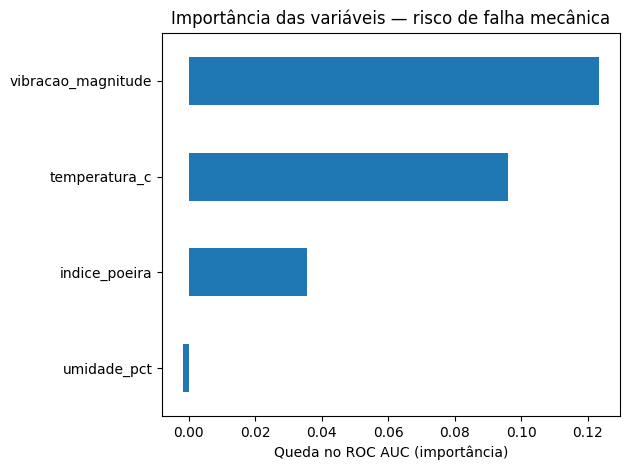

In [31]:
importancia_mecanico = permutation_importance(
    pipeline_mecanico_disponivel, X_mecd_teste, y_mecd_teste,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1,
)

importancia_mecanico_por_variavel = pd.Series(
    importancia_mecanico.importances_mean, index=X_mecd_teste.columns
).sort_values(ascending=False)

print("Importância por permutação (queda média no ROC AUC ao embaralhar cada variável):")
print(importancia_mecanico_por_variavel.round(4))

importancia_mecanico_por_variavel.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Queda no ROC AUC (importância)")
plt.title("Importância das variáveis — risco de falha mecânica")
plt.tight_layout()
plt.show()

## 16. Retreinar com 100% dos dados sintéticos

In [32]:
pipeline_mecanico_disponivel.fit(X_mec_disp, y_mec_disp)  # retreina com 100% do dataset sintético

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['temperatura_c','umidade_pct','indice_poeira','vibracao_magnitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns tha

## 17. Previsão final de risco de sinistro (a partir da chance de falha mecânica)

`temperatura_c` e `umidade_pct` vêm direto do DHT22, `indice_poeira` é
estimado a partir da umidade (mesma fórmula usada para gerar o treino) e
`vibracao_magnitude` vem do MPU6050 — as quatro variáveis que o firmware em
uso realmente mede, sem nenhum valor padrão/presumido escondido.

In [33]:
def preparar_features_mecanico_disponivel(df_leituras):
    umidade = df_leituras.get("umidade_pct")
    magnitude = df_leituras.get("aceleracao.magnitude")
    return pd.DataFrame({
        "temperatura_c": df_leituras.get("temperatura_c"),
        "umidade_pct": umidade,
        "indice_poeira": estimar_indice_poeira(umidade.fillna(umidade.mean())),
        "vibracao_magnitude": magnitude.fillna(9.80665) if magnitude is not None else 9.80665,
    })


def prever_risco_sinistro_por_falha_mecanica(caminho_arquivo_esp32, limiar=0.5):
    df_leituras = carregar_leituras_esp32(caminho_arquivo_esp32)
    if df_leituras.empty:
        print("Nenhuma leitura válida encontrada no arquivo.")
        return df_leituras

    features = preparar_features_mecanico_disponivel(df_leituras)
    probabilidades = pipeline_mecanico_disponivel.predict_proba(features)[:, 1]

    colunas_contexto = [c for c in [
        "id_leitura", "maquina", "timestamp", "status",
        "temperatura_c", "umidade_pct", "distancia_cm", "movimento",
    ] if c in df_leituras.columns]

    resultado = df_leituras[colunas_contexto].copy()
    resultado["probabilidade_sinistro"] = probabilidades.round(4)
    resultado["classificacao_ml"] = np.where(
        probabilidades >= limiar, "RISCO DE SINISTRO", "SEM RISCO RELEVANTE"
    )
    return resultado


resultado_final = prever_risco_sinistro_por_falha_mecanica(CAMINHO_ESP32)
resultado_final

[aviso] linha 9 ignorada (JSON inválido): 'E (34518) ledc: ledc_get_duty(745): LEDC is not initialized'
[info] 14 linha(s) sem 'id_leitura' ignoradas (mensagens de status/eventos, não leituras de sensor).


,id_leitura,maquina,timestamp,status,temperatura_c,umidade_pct,distancia_cm,movimento,probabilidade_sinistro,classificacao_ml
0,1,TRATOR-MT-01,2026-08-23T18:55:51Z,NORMAL,24.0,40.0,400.0,False,0.2959,SEM RISCO RELEVANTE
1,2,TRATOR-MT-01,2026-08-23T18:55:57Z,CRITICO,45.2,12.5,400.0,False,0.8468,RISCO DE SINISTRO
2,3,TRATOR-MT-01,2026-08-23T18:56:02Z,CRITICO,45.2,12.5,400.0,False,0.8468,RISCO DE SINISTRO
3,4,TRATOR-MT-01,2026-08-23T18:56:06Z,NORMAL,23.1,54.0,400.0,False,0.2180,SEM RISCO RELEVANTE
4,5,TRATOR-MT-01,2026-08-23T18:56:11Z,CRITICO,23.1,54.0,47.6,False,0.2180,SEM RISCO RELEVANTE
5,6,TRATOR-MT-01,2026-08-23T18:56:15Z,CRITICO,23.1,54.0,61.8,False,0.2180,SEM RISCO RELEVANTE
6,7,TRATOR-MT-01,2026-08-23T18:56:20Z,NORMAL,23.1,54.0,253.5,False,0.2180,SEM RISCO RELEVANTE
7,8,TRATOR-MT-01,2026-08-23T18:56:24Z,ATENCAO,23.1,54.0,400.0,False,0.6191,RISCO DE SINISTRO
8,9,TRATOR-MT-01,2026-08-23T18:56:29Z,ATENCAO,23.1,54.0,400.0,False,0.6191,RISCO DE SINISTRO
9,10,TRATOR-MT-01,2026-08-23T18:56:33Z,ATENCAO,23.1,54.0,400.0,False,0.6191,RISCO DE SINISTRO


In [34]:
import joblib
joblib.dump(pipeline_mecanico_disponivel, "modelo_risco_sinistro.joblib")
from google.colab import files
files.download("modelo_risco_sinistro.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Interpretação e Uso:**
- **Decisão do Grupo:** a `probabilidade_sinistro` é diretamente a probabilidade de falha mecânica, sem combinação com o modelo de risco ambiental da Parte 1. Essa é a previsão recomendada para o firmware atual.
- **Significado das Probabilidades:** As probabilidades variam de 0 a 1. Valores mais altos indicam maior chance de falha mecânica.
- **Ação:** As classificações de 'RISCO DE SINISTRO' podem ser usadas para acionar alertas ou investigações adicionais sobre a máquina. A probabilidade contínua também é útil para priorizar leituras ou para sistemas que requerem um nível de risco mais granular.

---
## Resumo das limitações

- O modelo só usa temperatura, umidade, latitude, longitude e cultura
  (com valor padrão) — distância, movimento e vibração do ESP32 não
  têm equivalente histórico no dataset de treino e por isso não entram na
  previsão de ML (mas continuam disponíveis via o `status` do firmware).
- Classes desbalanceadas (~7% de sinistro): trate a probabilidade contínua
  como mais informativa do que só o rótulo binário no limiar padrão de 0,5.
- Para evoluir este modelo de verdade, o próximo passo é substituir o
  rótulo do SISSER por um histórico real de sinistros/manutenção de
  máquinas agrícolas — e, idealmente, treinar com leituras instantâneas de
  campo (não médias climáticas), para eliminar o problema de extrapolação.

- **A Parte 2 (risco de falha mecânica) é inteiramente sintética/simulada**
  — Não existe hoje um dataset público real cruzando sensor ambiental com
  falha mecânica de máquina agrícola.